# London Food Hygiene Ratings: where is the risk?

**Question:** Which London boroughs and types of food business are most likely to have poor hygiene ratings, and is the inspection system keeping up?

**Data:** Food Standards Agency open data, all 33 London local authorities, extracted 18 Nov 2026 (81,764 businesses). Cleaned with `scripts/01_extract_clean.py`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold",  "font.size": 10})
BLUE, RED, GREY = "#1f4e79", "#c0392b", "#b0b7bf"

df = pd.read_csv("../data/london_food_hygiene_clean.csv", parse_dates=["rating_date"])
rated = df[df["rating_value"].notna()].copy()
print(f"{len(df):,} businesses, {len(rated):,} with a 0-5 rating, {df['borough'].nunique()} boroughs")

81,764 businesses, 71,741 with a 0-5 rating, 33 boroughs


## 1. Data quality checks

In [2]:
print("Duplicate IDs:", df["fhrs_id"].duplicated().sum())
print("\nRating status:\n", df["rating_status"].value_counts().to_string())
print("\nMissing values in rated rows (%):")
print((rated.isna().mean() * 100).round(1)[lambda s: s > 0].to_string())

Duplicate IDs: 0

Rating status:
 rating_status
Rated                  71741
AwaitingInspection      7288
Exempt                  2720
AwaitingPublication       15

Missing values in rated rows (%):
postcode                          10.6
score_hygiene                      1.1
score_structural                   1.1
score_confidence_in_management     1.1
latitude                          14.9
longitude                         14.9
postcode_district                 10.6


## 2. How are London's food businesses rated overall?

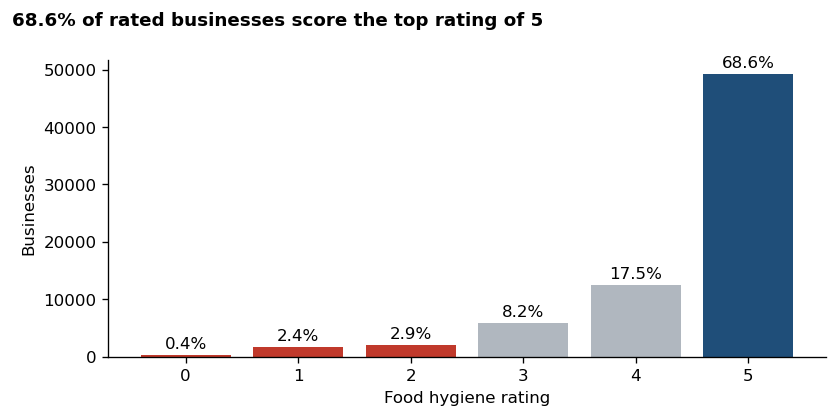

Low-rated (0-2): 5.7%


In [3]:
dist = rated["rating_value"].astype(int).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 3.5))
bars = ax.bar(dist.index.astype(str), dist.values, color=[RED, RED, RED, GREY, GREY, BLUE])
ax.bar_label(bars, labels=[f"{v/dist.sum():.1%}" for v in dist.values], padding=2)
fig.suptitle("68.6% of rated businesses score the top rating of 5", x=0.01, ha="left", fontweight="bold", fontsize=11)
ax.set(xlabel="Food hygiene rating", ylabel="Businesses")
plt.tight_layout(); plt.savefig("../images/01_rating_distribution.png"); plt.show()
print(f"Low-rated (0-2): {(rated['rating_value'] <= 2).mean():.1%}")

## 3. Which boroughs have the highest share of low-rated businesses?

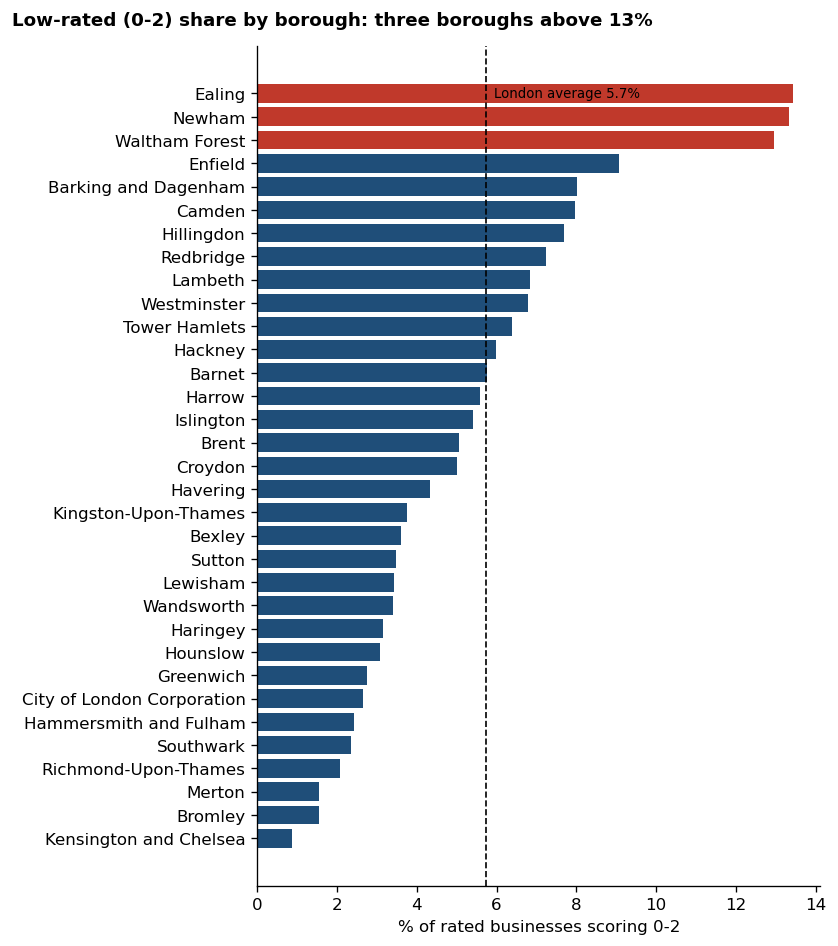

Highest: Ealing 13.4%  Lowest: Kensington and Chelsea 0.9%  Ratio: 15x


In [4]:
b = (rated.groupby("borough")["low_rating_flag"].mean().mul(100).sort_values())
fig, ax = plt.subplots(figsize=(7, 8))
colors = [RED if v >= 10 else BLUE for v in b.values]
ax.barh(b.index, b.values, color=colors)
ax.axvline((rated["low_rating_flag"].mean() * 100), color="black", ls="--", lw=1)
ax.text(rated["low_rating_flag"].mean() * 100 + 0.2, len(b) - 1, "London average 5.7%", fontsize=8, va="center")
fig.suptitle("Low-rated (0-2) share by borough: three boroughs above 13%", x=0.01, ha="left", fontweight="bold", fontsize=11)
ax.set(xlabel="% of rated businesses scoring 0-2")
plt.tight_layout(); plt.savefig("../images/02_low_rated_by_borough.png"); plt.show()
print(f"Highest: {b.idxmax()} {b.max():.1f}%  Lowest: {b.idxmin()} {b.min():.1f}%  Ratio: {b.max()/b.min():.0f}x")

## 4. Which types of business carry the most risk?

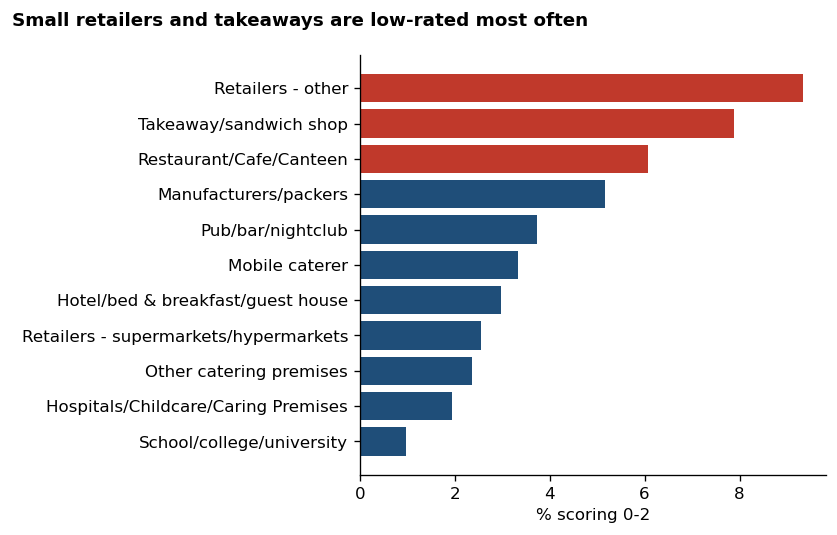

,n,low
business_type,,
School/college/university,3273,1.0
Hospitals/Childcare/Caring Premises,4343,1.9
Other catering premises,6145,2.4
Retailers - supermarkets/hypermarkets,2269,2.6
Hotel/bed & breakfast/guest house,941,3.0
Mobile caterer,1975,3.3
Pub/bar/nightclub,3704,3.7
Manufacturers/packers,871,5.2
Restaurant/Cafe/Canteen,25449,6.1


In [5]:
t = (rated.groupby("business_type").agg(n=("fhrs_id", "size"), low=("low_rating_flag", "mean"))
       .query("n >= 500").assign(low=lambda d: d["low"] * 100).sort_values("low"))
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(t.index, t["low"], color=[RED if v >= 6 else BLUE for v in t["low"]])
fig.suptitle("Small retailers and takeaways are low-rated most often", x=0.01, ha="left", fontweight="bold", fontsize=11)
ax.set(xlabel="% scoring 0-2")
plt.tight_layout(); plt.savefig("../images/03_low_rated_by_business_type.png"); plt.show()
t.round(1)

## 5. Is the inspection system keeping up?

Recent inspections show *lower* ratings. That is expected because councils inspect high-risk businesses more often, so a business with an old inspection date was usually rated well last time. The real risk is the backlog of businesses that have never been inspected.

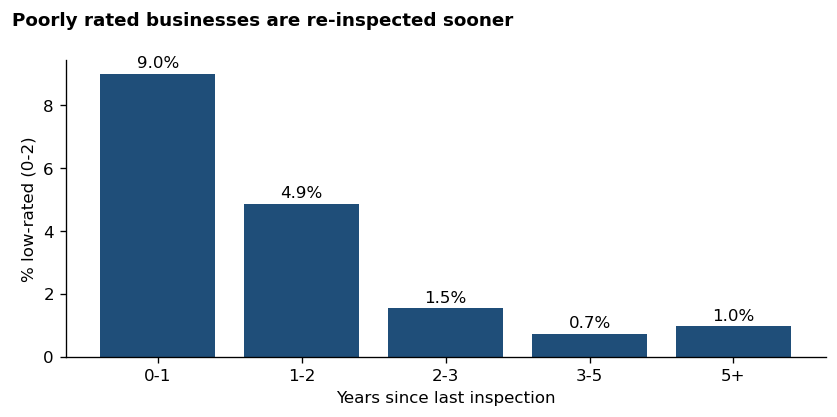

Awaiting first inspection, % of all businesses (top 5):
borough
Camden       19.2
Hounslow     18.1
Merton       16.0
Redbridge    15.9
Harrow       15.0


In [6]:
bins = [0, 1, 2, 3, 5, 100]
labels = ["0-1", "1-2", "2-3", "3-5", "5+"]
rated["since"] = pd.cut(rated["years_since_inspection"], bins=bins, labels=labels, right=False)
s = rated.groupby("since", observed=True)["low_rating_flag"].mean().mul(100)
fig, ax = plt.subplots(figsize=(7, 3.5))
bars = ax.bar(s.index.astype(str), s.values, color=BLUE)
ax.bar_label(bars, labels=[f"{v:.1f}%" for v in s.values], padding=2)
fig.suptitle("Poorly rated businesses are re-inspected sooner", x=0.01, ha="left", fontweight="bold", fontsize=11)
ax.set(xlabel="Years since last inspection", ylabel="% low-rated (0-2)")
plt.tight_layout(); plt.savefig("../images/04_rating_by_inspection_age.png"); plt.show()

awaiting = df.groupby("borough")["rating_status"].apply(lambda s: (s == "AwaitingInspection").mean() * 100).sort_values(ascending=False)
print("Awaiting first inspection, % of all businesses (top 5):")
print(awaiting.head().round(1).to_string())

## Key findings

1. **Most businesses are safe:** 68.6% score 5 and only 5.7% score 0-2.
2. **Risk is concentrated:** Ealing (13.4%), Newham (13.3%) and Waltham Forest (13.0%) have the highest share of low-rated businesses. That is around 15 times Kensington and Chelsea (0.9%).
3. **Sector matters:** small retailers (9.3%) and takeaways (7.9%) are low-rated far more often than schools (1.0%) or supermarkets (2.6%).
4. **Management drives the worst ratings:** businesses rated 0 average 25.2 on *confidence in management*, worse than their hygiene (18.5) or structural (20.3) scores.
5. **Inspection backlog:** in Camden, about 19% of businesses are still waiting for their first inspection.

**Recommendation:** councils with a high share of low ratings and a large backlog (Camden, Ealing) should prioritise first inspections of new takeaways and small retailers, and focus advice on food safety management systems.